# 특허소송예측 — 최종 모델 개발
**목표**: 피처 선택 + 하이퍼파라미터 튜닝으로 최적 모델 확정 후 저장

## 진행 순서
1. 데이터 로드 및 피처 완성도 확인
2. 현재 모델(v2) SHAP 피처 중요도 분석
3. 피처 선택 실험 (전체 27개 / Top-N / 희소 피처 제거)
4. Optuna 하이퍼파라미터 튜닝 (피처셋별)
5. 최적 조합 선택 및 최종 모델 저장

In [22]:
import pandas as pd
import numpy as np
import pickle
import warnings
import subprocess
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import shap
import optuna
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
import lightgbm as lgb

# 한국어 폰트 자동 감지
_korean_fonts = ['NanumGothic', 'NanumBarunGothic', 'UnDotum', 'Malgun Gothic', 'AppleGothic']
_available = {f.name for f in fm.fontManager.ttflist}
_font = next((f for f in _korean_fonts if f in _available), 'DejaVu Sans')
matplotlib.rcParams['font.family'] = _font
matplotlib.rcParams['axes.unicode_minus'] = False
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# GPU 사용 가능 여부 자동 감지
def _check_lgb_gpu():
    try:
        import numpy as np
        m = lgb.LGBMClassifier(device='gpu', n_estimators=5, verbose=-1)
        m.fit(np.random.rand(50, 3), np.random.randint(0, 2, 50))
        return True
    except:
        return False

USE_GPU = _check_lgb_gpu()
DEVICE  = 'gpu' if USE_GPU else 'cpu'

try:
    _smi = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                          capture_output=True, text=True, timeout=3)
    print('GPU 정보:', _smi.stdout.strip())
except:
    print('GPU 정보: nvidia-smi 없음')

print(f'LightGBM device: {DEVICE}')
print(f'사용 폰트: {_font}')

DATA_DIR     = './data_v2'
RANDOM_STATE = 42

FEATURE_COLS = [
    'MCD', 'SCD',
    'TD_A', 'TD_B', 'TD_C', 'TD_D', 'TD_E', 'TD_F', 'TD_G', 'TD_H',
    'ABS', 'CTS', 'CTC', 'PTS',
    'PK', 'SK', 'PPS',
    'CD', 'IC', 'IE', 'FIE', 'ET',
    'TCP',
    'LI1', 'LI3', 'LI5', 'LI7'
]
print(f'피처 수: {len(FEATURE_COLS)} | 환경 설정 완료')

GPU 정보: NVIDIA GeForce RTX 3090, 24576 MiB
LightGBM device: gpu
사용 폰트: NanumGothic
피처 수: 27 | 환경 설정 완료


#### Step 1. 데이터 로드 및 피처 완성도 확인

In [23]:
df_model1 = pd.read_pickle(f'{DATA_DIR}/df_model1_features.pkl')
df_model2 = pd.read_pickle(f'{DATA_DIR}/df_model2_features.pkl')

feat_cols = [c for c in FEATURE_COLS if c in df_model1.columns]
print(f'Model1: {len(df_model1):,}건  (L={df_model1["label"].sum():,} / NL={(df_model1["label"]==0).sum():,})')
print(f'Model2: {len(df_model2):,}건')
print(f'사용 피처: {len(feat_cols)}개')

Model1: 5,688,033건  (L=33,657 / NL=5,654,376)
Model2: 29,950건
사용 피처: 27개


In [24]:
# 피처 완성도 — L/NL 각 5,000건 샘플 기준
sample = pd.concat([
    df_model1[df_model1['label']==1].sample(min(5000, int(df_model1['label'].sum())), random_state=RANDOM_STATE),
    df_model1[df_model1['label']==0].sample(5000, random_state=RANDOM_STATE)
])

completeness = pd.DataFrame({
    'non_zero_pct': [(sample[c] != 0).mean() * 100 for c in feat_cols],
    'mean':         [sample[c].mean() for c in feat_cols],
    'std':          [sample[c].std()  for c in feat_cols],
}, index=feat_cols).sort_values('non_zero_pct')

print('=== 피처 완성도 (non-zero %) ===')
print(completeness.round(2).to_string())

# 희소 피처 (non-zero < 10%) 식별
sparse_feats = completeness[completeness['non_zero_pct'] < 10].index.tolist()
print(f'\n희소 피처 (<10% non-zero): {sparse_feats}')

=== 피처 완성도 (non-zero %) ===
      non_zero_pct     mean      std
TD_D          0.82     0.01     0.09
TD_E          3.37     0.03     0.18
TD_F          8.09     0.08     0.27
TD_C          9.50     0.10     0.29
LI1          16.26     0.39     2.02
TD_B         16.36     0.16     0.37
TD_A         20.40     0.20     0.40
LI3          20.47     0.69     3.53
LI5          21.76     0.84     4.29
LI7          22.41     0.91     4.51
TD_H         25.04     0.25     0.43
PPS          25.69     0.26     0.45
TD_G         32.79     0.33     0.47
TCP          38.00   608.89  4299.82
SK           53.71    12.87    59.62
PTS          83.05     2.81     3.14
CTC          83.05  1008.19  1185.53
CTS          83.05    17.40    19.79
PK           94.97    25.06    88.48
IC           99.76     1.00     0.09
ABS          99.96   116.60    49.97
SCD          99.98     1.39     0.84
MCD          99.98     1.26     0.62
CD          100.00     1.02     0.17
IE          100.00     2.48     1.91
FIE       

---
#### Step 2. 현재 모델(v2) SHAP 피처 중요도 분석

Model1 v2: LightGBM  feat_cols=27개
Model2 v2: LightGBM  feat_cols=27개

=== Model1 SHAP 피처 중요도 (상위 27개) ===
TCP     4.2641
LI7     1.3922
PPS     0.2980
IE      0.1837
PK      0.1732
CTC     0.1683
CTS     0.1447
PTS     0.1157
TD_C    0.0955
TD_H    0.0915
ABS     0.0685
TD_A    0.0684
ET      0.0633
SK      0.0525
SCD     0.0456
TD_G    0.0285
MCD     0.0186
IC      0.0132
FIE     0.0102
TD_E    0.0092
TD_F    0.0070
TD_B    0.0060
TD_D    0.0018
CD      0.0008
LI1     0.0000
LI3     0.0000
LI5     0.0000


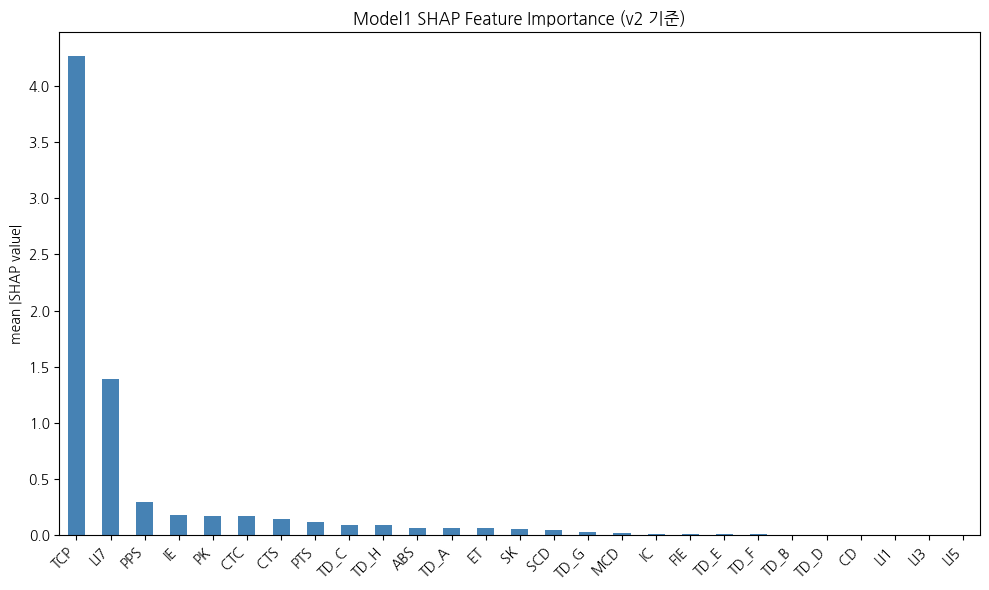

In [25]:
# 기존 v2 모델 로드
with open(f'{DATA_DIR}/model1_v2_best.pkl', 'rb') as f:
    m1 = pickle.load(f)
with open(f'{DATA_DIR}/model2_v2_best.pkl', 'rb') as f:
    m2 = pickle.load(f)

print(f'Model1 v2: {m1["name"]}  feat_cols={len(m1["feat_cols"])}개')
print(f'Model2 v2: {m2["name"]}  feat_cols={len(m2["feat_cols"])}개')

# SHAP — Model1 (균형 샘플 2,000건)
shap_sample = pd.concat([
    df_model1[df_model1['label']==1].sample(1000, random_state=RANDOM_STATE),
    df_model1[df_model1['label']==0].sample(1000, random_state=RANDOM_STATE)
])
X_shap = shap_sample[m1['feat_cols']].values

explainer1 = shap.TreeExplainer(m1['model'])
shap_vals1 = explainer1.shap_values(X_shap)
if isinstance(shap_vals1, list):
    shap_vals1 = shap_vals1[1]

shap_imp1 = pd.Series(
    np.abs(shap_vals1).mean(axis=0),
    index=m1['feat_cols']
).sort_values(ascending=False)

print('\n=== Model1 SHAP 피처 중요도 (상위 27개) ===')
print(shap_imp1.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 6))
shap_imp1.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Model1 SHAP Feature Importance (v2 기준)')
ax.set_ylabel('mean |SHAP value|')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/shap_m1_v2.png', dpi=150)
plt.show()

=== Model2 SHAP 피처 중요도 ===
LI3     0.7346
LI1     0.5736
LI7     0.3659
TCP     0.3145
LI5     0.1745
ET      0.1147
TD_B    0.1068
ABS     0.0950
TD_G    0.0785
TD_H    0.0713
CTS     0.0697
PK      0.0636
TD_F    0.0585
CTC     0.0583
SK      0.0468
IE      0.0458
PTS     0.0432
SCD     0.0319
TD_A    0.0176
TD_C    0.0167
PPS     0.0160
TD_E    0.0157
MCD     0.0062
CD      0.0052
TD_D    0.0047
FIE     0.0045
IC      0.0000


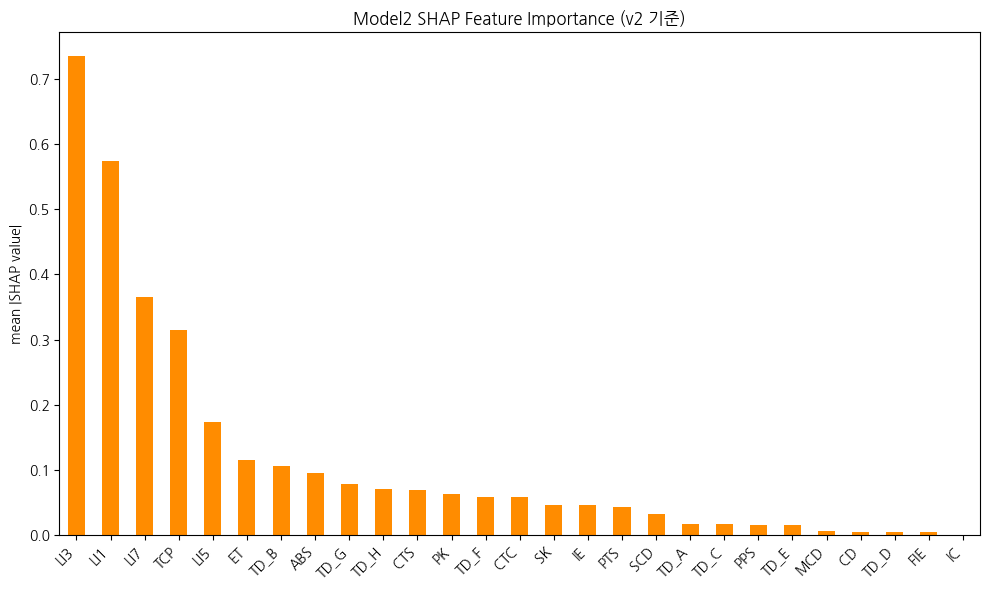

In [26]:
# SHAP — Model2
X_shap2 = df_model2[m2['feat_cols']].sample(2000, random_state=RANDOM_STATE).values

explainer2 = shap.TreeExplainer(m2['model'])
shap_vals2 = explainer2.shap_values(X_shap2)
if isinstance(shap_vals2, list):
    shap_vals2 = shap_vals2[1]

shap_imp2 = pd.Series(
    np.abs(shap_vals2).mean(axis=0),
    index=m2['feat_cols']
).sort_values(ascending=False)

print('=== Model2 SHAP 피처 중요도 ===')
print(shap_imp2.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 6))
shap_imp2.plot(kind='bar', ax=ax, color='darkorange')
ax.set_title('Model2 SHAP Feature Importance (v2 기준)')
ax.set_ylabel('mean |SHAP value|')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/shap_m2_v2.png', dpi=150)
plt.show()

---
## Step 3. 피처셋 정의

SHAP 결과를 보고 아래 셋을 수정하세요.

| 셋 | 설명 |
|---|---|
| `feat_all` | 전체 27개 (baseline) |
| `feat_no_sparse` | 희소 피처(<10%) 제거 |
| `feat_top15` | SHAP 상위 15개 |
| `feat_top10` | SHAP 상위 10개 |

In [27]:
# ── Model1 피처셋 (SHAP 기준: TCP·LI7 압도적, LI1/LI3/LI5≈0)
M1_FEAT_SETS = {
    'all_27':    feat_cols,
    # TD_D(0.8% non-zero), CD·LI1·LI3·LI5(SHAP≈0) 제거
    'no_zero_m1': [f for f in feat_cols if f not in ['TD_D','CD','LI1','LI3','LI5']],
    # SHAP 상위 15
    'top15_m1':  shap_imp1.head(15).index.tolist(),
    # SHAP 상위 10
    'top10_m1':  shap_imp1.head(10).index.tolist(),
}

# ── Model2 피처셋 (SHAP 기준: LI1·LI3·LI5 핵심, IC·FIE·CD·MCD≈0)
M2_FEAT_SETS = {
    'all_27':    feat_cols,
    # IC·FIE·TD_D·CD·MCD(SHAP≈0) 제거
    'no_zero_m2': [f for f in feat_cols if f not in ['IC','FIE','TD_D','CD','MCD']],
    # SHAP 상위 15
    'top15_m2':  shap_imp2.head(15).index.tolist(),
    # SHAP 상위 10
    'top10_m2':  shap_imp2.head(10).index.tolist(),
}

print('=== Model1 피처셋 ===')
for name, fs in M1_FEAT_SETS.items():
    print(f'  {name:12s} ({len(fs)}개): {fs}')

print('\n=== Model2 피처셋 ===')
for name, fs in M2_FEAT_SETS.items():
    print(f'  {name:12s} ({len(fs)}개): {fs}')

=== Model1 피처셋 ===
  all_27       (27개): ['MCD', 'SCD', 'TD_A', 'TD_B', 'TD_C', 'TD_D', 'TD_E', 'TD_F', 'TD_G', 'TD_H', 'ABS', 'CTS', 'CTC', 'PTS', 'PK', 'SK', 'PPS', 'CD', 'IC', 'IE', 'FIE', 'ET', 'TCP', 'LI1', 'LI3', 'LI5', 'LI7']
  no_zero_m1   (22개): ['MCD', 'SCD', 'TD_A', 'TD_B', 'TD_C', 'TD_E', 'TD_F', 'TD_G', 'TD_H', 'ABS', 'CTS', 'CTC', 'PTS', 'PK', 'SK', 'PPS', 'IC', 'IE', 'FIE', 'ET', 'TCP', 'LI7']
  top15_m1     (15개): ['TCP', 'LI7', 'PPS', 'IE', 'PK', 'CTC', 'CTS', 'PTS', 'TD_C', 'TD_H', 'ABS', 'TD_A', 'ET', 'SK', 'SCD']
  top10_m1     (10개): ['TCP', 'LI7', 'PPS', 'IE', 'PK', 'CTC', 'CTS', 'PTS', 'TD_C', 'TD_H']

=== Model2 피처셋 ===
  all_27       (27개): ['MCD', 'SCD', 'TD_A', 'TD_B', 'TD_C', 'TD_D', 'TD_E', 'TD_F', 'TD_G', 'TD_H', 'ABS', 'CTS', 'CTC', 'PTS', 'PK', 'SK', 'PPS', 'CD', 'IC', 'IE', 'FIE', 'ET', 'TCP', 'LI1', 'LI3', 'LI5', 'LI7']
  no_zero_m2   (22개): ['SCD', 'TD_A', 'TD_B', 'TD_C', 'TD_E', 'TD_F', 'TD_G', 'TD_H', 'ABS', 'CTS', 'CTC', 'PTS', 'PK', 'SK', 'PPS', '

---
#### Step 4. 하이퍼파라미터 튜닝 (Optuna)

- Model1: 균형 Train 셋(5만건)으로 3-Fold CV AUC 최적화
- Model2: 전체 학습 데이터 3-Fold CV AUC 최적화
- 각 피처셋마다 독립적으로 튜닝

In [28]:
# Model1 Train 셋 구성 (v2와 동일 방식)
df_L  = df_model1[df_model1['label'] == 1].reset_index(drop=True)
df_NL = df_model1[df_model1['label'] == 0].reset_index(drop=True)

L_train, L_test        = train_test_split(df_L,  test_size=0.2, random_state=RANDOM_STATE)
NL_train_pool, NL_test = train_test_split(df_NL, test_size=0.2, random_state=RANDOM_STATE)

n_needed    = len(L_train)
NL_complete = NL_train_pool[NL_train_pool['claims_observed'] == 1]
NL_incomp   = NL_train_pool[NL_train_pool['claims_observed'] == 0]
if len(NL_complete) >= n_needed:
    NL_train = NL_complete.sample(n=n_needed, random_state=RANDOM_STATE)
else:
    extra = n_needed - len(NL_complete)
    NL_train = pd.concat([NL_complete, NL_incomp.sample(n=extra, random_state=RANDOM_STATE)])

train_m1 = pd.concat([L_train, NL_train]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
test_m1  = pd.concat([L_test,  NL_test ]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print(f'Model1 Train: {len(train_m1):,}건  Test: {len(test_m1):,}건 (NL:L={(( test_m1["label"]==0).sum()/test_m1["label"].sum()):.0f}:1)')

# Model2 분리 — feat_cols(전체 27개) 기준으로 X 구성, 튜닝 셀에서 피처셋별 슬라이싱
X_m2 = df_model2[feat_cols].values
y_m2 = df_model2['label_L1L2'].values
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_m2, y_m2, test_size=0.2, stratify=y_m2, random_state=RANDOM_STATE)
print(f'Model2 Train: {len(X_tr2):,}건  Test: {len(X_te2):,}건')

Model1 Train: 53,850건  Test: 1,137,608건 (NL:L=168:1)
Model2 Train: 23,960건  Test: 5,990건


In [29]:
def _lgb_params(trial, extra=None):
    p = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500, step=100),  # 1000→500
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 20, 150),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'device':            DEVICE,
        'n_jobs':            1,      # GPU 사용 시 CPU 병렬화 off
        'random_state':      RANDOM_STATE,
        'verbose':           -1,
    }
    if extra:
        p.update(extra)
    return p


def make_objective_m1(feat_set, df_train):
    X = df_train[feat_set].values
    y = df_train['label'].values
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    def objective(trial):
        model = lgb.LGBMClassifier(**_lgb_params(trial))
        aucs = []
        for tr_idx, val_idx in cv.split(X, y):
            model.fit(X[tr_idx], y[tr_idx])
            proba = model.predict_proba(X[val_idx])[:, 1]
            aucs.append(roc_auc_score(y[val_idx], proba))
        return np.mean(aucs)
    return objective


def make_objective_m2(X_train, y_train, spw):
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    def objective(trial):
        model = lgb.LGBMClassifier(**_lgb_params(trial, extra={'scale_pos_weight': spw}))
        aucs = []
        for tr_idx, val_idx in cv.split(X_train, y_train):
            model.fit(X_train[tr_idx], y_train[tr_idx])
            proba = model.predict_proba(X_train[val_idx])[:, 1]
            aucs.append(roc_auc_score(y_train[val_idx], proba))
        return np.mean(aucs)
    return objective


print(f'Optuna objective 함수 정의 완료  (device={DEVICE}, n_jobs=1, n_estimators≤500)')

Optuna objective 함수 정의 완료  (device=gpu, n_jobs=1, n_estimators≤500)


In [30]:
# Model1 피처셋별 Optuna 튜닝
N_TRIALS  = 40
TIMEOUT   = 300  # 피처셋당 최대 5분 (먼저 도달하는 쪽에서 종료)
results_tune_m1 = {}

for set_name, fs in M1_FEAT_SETS.items():
    print(f'\n[Model1] {set_name} ({len(fs)}개 피처) 튜닝 중...')
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
    )
    study.optimize(
        make_objective_m1(fs, train_m1),
        n_trials=N_TRIALS,
        timeout=TIMEOUT,
        show_progress_bar=True   # 진행 상황 표시
    )

    best_params = study.best_params
    best_cv_auc = study.best_value
    print(f'  완료 trials={len(study.trials)}  Best CV AUC={best_cv_auc:.4f}')
    print(f'  Best params: {best_params}')

    X_tr = train_m1[fs].values;  y_tr = train_m1['label'].values
    X_te = test_m1[fs].values;   y_te = test_m1['label'].values

    model = lgb.LGBMClassifier(**best_params, device=DEVICE, n_jobs=1, random_state=RANDOM_STATE, verbose=-1)
    model.fit(X_tr, y_tr)
    print(f'  최종 모델 학습 완료, Test 평가 중...')
    proba    = model.predict_proba(X_te)[:, 1]
    test_auc = roc_auc_score(y_te, proba)
    test_ap  = average_precision_score(y_te, proba)

    results_tune_m1[set_name] = {
        'feat_set': fs, 'n_feats': len(fs),
        'cv_auc': best_cv_auc, 'test_auc': test_auc, 'test_ap': test_ap,
        'best_params': best_params, 'model': model
    }
    print(f'  Test AUC={test_auc:.4f}  AP={test_ap:.4f}')

print('\n=== Model1 피처셋별 결과 요약 ===')
print(f'  (v2 baseline: AUC=0.9577  AP=0.8532)')
summary_m1 = pd.DataFrame({
    k: {'피처수': v['n_feats'], 'CV_AUC': v['cv_auc'], 'Test_AUC': v['test_auc'], 'Test_AP': v['test_ap']}
    for k, v in results_tune_m1.items()
}).T
print(summary_m1.round(4).to_string())


[Model1] all_27 (27개 피처) 튜닝 중...


Best trial: 35. Best value: 0.962671: 100%|██████████| 40/40 [04:52<00:00,  7.31s/it, 292.30/300 seconds]


  완료 trials=40  Best CV AUC=0.9627
  Best params: {'n_estimators': 500, 'learning_rate': 0.011780723720446256, 'num_leaves': 132, 'max_depth': 9, 'min_child_samples': 10, 'subsample': 0.6821490938021455, 'colsample_bytree': 0.7343557527202633, 'reg_alpha': 0.002003700742754417, 'reg_lambda': 0.3865640241387644}
  최종 모델 학습 완료, Test 평가 중...
  Test AUC=0.9582  AP=0.8527

[Model1] no_zero_m1 (22개 피처) 튜닝 중...


Best trial: 32. Best value: 0.962797: 100%|██████████| 40/40 [04:56<00:00,  7.42s/it, 296.68/300 seconds]


  완료 trials=40  Best CV AUC=0.9628
  Best params: {'n_estimators': 500, 'learning_rate': 0.015383702831660557, 'num_leaves': 79, 'max_depth': 9, 'min_child_samples': 34, 'subsample': 0.7050002501754312, 'colsample_bytree': 0.6031763464480447, 'reg_alpha': 0.0023161351194038475, 'reg_lambda': 0.004919092980839735}
  최종 모델 학습 완료, Test 평가 중...
  Test AUC=0.9667  AP=0.8589

[Model1] top15_m1 (15개 피처) 튜닝 중...


Best trial: 22. Best value: 0.962414: 100%|██████████| 40/40 [04:53<00:00,  7.33s/it, 293.33/300 seconds]


  완료 trials=40  Best CV AUC=0.9624
  Best params: {'n_estimators': 500, 'learning_rate': 0.010428923776150793, 'num_leaves': 150, 'max_depth': 10, 'min_child_samples': 63, 'subsample': 0.8914576154948034, 'colsample_bytree': 0.5645646226798079, 'reg_alpha': 0.3056058157685993, 'reg_lambda': 0.028912644384523085}
  최종 모델 학습 완료, Test 평가 중...
  Test AUC=0.9676  AP=0.8593

[Model1] top10_m1 (10개 피처) 튜닝 중...


Best trial: 32. Best value: 0.960198: 100%|██████████| 40/40 [02:51<00:00,  4.28s/it, 171.21/300 seconds]


  완료 trials=40  Best CV AUC=0.9602
  Best params: {'n_estimators': 400, 'learning_rate': 0.011871337433326433, 'num_leaves': 35, 'max_depth': 9, 'min_child_samples': 19, 'subsample': 0.9994902667235264, 'colsample_bytree': 0.5615317806735084, 'reg_alpha': 0.8263558186760167, 'reg_lambda': 0.8197983394151157}
  최종 모델 학습 완료, Test 평가 중...
  Test AUC=0.9544  AP=0.8497

=== Model1 피처셋별 결과 요약 ===
  (v2 baseline: AUC=0.9577  AP=0.8532)
             피처수  CV_AUC  Test_AUC  Test_AP
all_27      27.0  0.9627    0.9582   0.8527
no_zero_m1  22.0  0.9628    0.9667   0.8589
top15_m1    15.0  0.9624    0.9676   0.8593
top10_m1    10.0  0.9602    0.9544   0.8497


In [31]:
# Model2 피처셋별 Optuna 튜닝
N_TRIALS  = 40
TIMEOUT   = 300
results_tune_m2 = {}

spw = (y_tr2 == 0).sum() / (y_tr2 == 1).sum()
print(f'Model2 scale_pos_weight: {spw:.2f}')

for set_name, fs in M2_FEAT_SETS.items():
    print(f'\n[Model2] {set_name} ({len(fs)}개 피처) 튜닝 중...')

    # feat_cols 순서 기준 열 인덱스 슬라이싱
    col_idx = [feat_cols.index(f) for f in fs]
    X_tr = X_tr2[:, col_idx]
    X_te = X_te2[:, col_idx]

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
    )
    study.optimize(
        make_objective_m2(X_tr, y_tr2, spw),
        n_trials=N_TRIALS,
        timeout=TIMEOUT,
        show_progress_bar=True
    )

    best_params = study.best_params
    best_cv_auc = study.best_value
    print(f'  완료 trials={len(study.trials)}  Best CV AUC={best_cv_auc:.4f}')
    print(f'  Best params: {best_params}')

    model = lgb.LGBMClassifier(
        **best_params, scale_pos_weight=spw,
        device=DEVICE, n_jobs=1, random_state=RANDOM_STATE, verbose=-1
    )
    model.fit(X_tr, y_tr2)
    print(f'  최종 모델 학습 완료, Test 평가 중...')
    proba    = model.predict_proba(X_te)[:, 1]
    test_auc = roc_auc_score(y_te2, proba)
    test_ap  = average_precision_score(y_te2, proba)

    results_tune_m2[set_name] = {
        'feat_set': fs, 'n_feats': len(fs),
        'cv_auc': best_cv_auc, 'test_auc': test_auc, 'test_ap': test_ap,
        'best_params': best_params, 'model': model
    }
    print(f'  Test AUC={test_auc:.4f}  AP={test_ap:.4f}')

print('\n=== Model2 피처셋별 결과 요약 ===')
print(f'  (v2 baseline: AUC=0.9515)')
summary_m2 = pd.DataFrame({
    k: {'피처수': v['n_feats'], 'CV_AUC': v['cv_auc'], 'Test_AUC': v['test_auc'], 'Test_AP': v['test_ap']}
    for k, v in results_tune_m2.items()
}).T
print(summary_m2.round(4).to_string())

Model2 scale_pos_weight: 4.18

[Model2] all_27 (27개 피처) 튜닝 중...


Best trial: 39. Best value: 0.949624: 100%|██████████| 40/40 [02:56<00:00,  4.42s/it, 176.87/300 seconds]


  완료 trials=40  Best CV AUC=0.9496
  Best params: {'n_estimators': 400, 'learning_rate': 0.11416014818200051, 'num_leaves': 109, 'max_depth': 10, 'min_child_samples': 14, 'subsample': 0.8552655450501062, 'colsample_bytree': 0.5319920554221101, 'reg_alpha': 0.0021370478907085538, 'reg_lambda': 0.004126218910719801}
  최종 모델 학습 완료, Test 평가 중...
  Test AUC=0.9525  AP=0.9190

[Model2] no_zero_m2 (22개 피처) 튜닝 중...


Best trial: 0. Best value: 0.94882: 100%|██████████| 40/40 [02:24<00:00,  3.61s/it, 144.21/300 seconds]


  완료 trials=40  Best CV AUC=0.9488
  Best params: {'n_estimators': 200, 'learning_rate': 0.17254716573280354, 'num_leaves': 115, 'max_depth': 7, 'min_child_samples': 24, 'subsample': 0.5779972601681014, 'colsample_bytree': 0.5290418060840998, 'reg_alpha': 2.9154431891537547, 'reg_lambda': 0.2537815508265665}
  최종 모델 학습 완료, Test 평가 중...
  Test AUC=0.9508  AP=0.9150

[Model2] top15_m2 (15개 피처) 튜닝 중...


Best trial: 33. Best value: 0.947541: 100%|██████████| 40/40 [02:25<00:00,  3.64s/it, 145.58/300 seconds]


  완료 trials=40  Best CV AUC=0.9475
  Best params: {'n_estimators': 500, 'learning_rate': 0.04329269809598105, 'num_leaves': 99, 'max_depth': 10, 'min_child_samples': 87, 'subsample': 0.5649747493905836, 'colsample_bytree': 0.6617009351206832, 'reg_alpha': 0.6635779035463584, 'reg_lambda': 0.0672646232167401}
  최종 모델 학습 완료, Test 평가 중...
  Test AUC=0.9510  AP=0.9134

[Model2] top10_m2 (10개 피처) 튜닝 중...


Best trial: 19. Best value: 0.950916: 100%|██████████| 40/40 [02:10<00:00,  3.26s/it, 130.51/300 seconds]


  완료 trials=40  Best CV AUC=0.9509
  Best params: {'n_estimators': 400, 'learning_rate': 0.04186176009296456, 'num_leaves': 72, 'max_depth': 9, 'min_child_samples': 39, 'subsample': 0.7231610042250181, 'colsample_bytree': 0.5066530769961229, 'reg_alpha': 0.04705614323574565, 'reg_lambda': 0.450062550183456}
  최종 모델 학습 완료, Test 평가 중...
  Test AUC=0.9512  AP=0.9143

=== Model2 피처셋별 결과 요약 ===
  (v2 baseline: AUC=0.9515)
             피처수  CV_AUC  Test_AUC  Test_AP
all_27      27.0  0.9496    0.9525   0.9190
no_zero_m2  22.0  0.9488    0.9508   0.9150
top15_m2    15.0  0.9475    0.9510   0.9134
top10_m2    10.0  0.9509    0.9512   0.9143


In [32]:
# 최적 피처셋 선택 — Test AUC 기준
best_m1_name = max(results_tune_m1, key=lambda k: results_tune_m1[k]['test_auc'])
best_m2_name = max(results_tune_m2, key=lambda k: results_tune_m2[k]['test_auc'])

best_m1 = results_tune_m1[best_m1_name]
best_m2 = results_tune_m2[best_m2_name]

print('=== 최종 모델 선택 결과 ===')
print(f'\n[Model1] 최적 피처셋: {best_m1_name}')
print(f'  피처수: {best_m1["n_feats"]}개')
print(f'  피처: {best_m1["feat_set"]}')
print(f'  CV AUC:   {best_m1["cv_auc"]:.4f}')
print(f'  Test AUC: {best_m1["test_auc"]:.4f}  (v2 baseline: 0.9577, 개선: {best_m1["test_auc"]-0.9577:+.4f})')
print(f'  Test AP:  {best_m1["test_ap"]:.4f}  (v2 baseline: 0.8532, 개선: {best_m1["test_ap"]-0.8532:+.4f})')
print(f'  Best params: {best_m1["best_params"]}')

print(f'\n[Model2] 최적 피처셋: {best_m2_name}')
print(f'  피처수: {best_m2["n_feats"]}개')
print(f'  피처: {best_m2["feat_set"]}')
print(f'  CV AUC:   {best_m2["cv_auc"]:.4f}')
print(f'  Test AUC: {best_m2["test_auc"]:.4f}  (v2 baseline: 0.9515, 개선: {best_m2["test_auc"]-0.9515:+.4f})')
print(f'  Test AP:  {best_m2["test_ap"]:.4f}')
print(f'  Best params: {best_m2["best_params"]}')

=== 최종 모델 선택 결과 ===

[Model1] 최적 피처셋: top15_m1
  피처수: 15개
  피처: ['TCP', 'LI7', 'PPS', 'IE', 'PK', 'CTC', 'CTS', 'PTS', 'TD_C', 'TD_H', 'ABS', 'TD_A', 'ET', 'SK', 'SCD']
  CV AUC:   0.9624
  Test AUC: 0.9676  (v2 baseline: 0.9577, 개선: +0.0099)
  Test AP:  0.8593  (v2 baseline: 0.8532, 개선: +0.0061)
  Best params: {'n_estimators': 500, 'learning_rate': 0.010428923776150793, 'num_leaves': 150, 'max_depth': 10, 'min_child_samples': 63, 'subsample': 0.8914576154948034, 'colsample_bytree': 0.5645646226798079, 'reg_alpha': 0.3056058157685993, 'reg_lambda': 0.028912644384523085}

[Model2] 최적 피처셋: all_27
  피처수: 27개
  피처: ['MCD', 'SCD', 'TD_A', 'TD_B', 'TD_C', 'TD_D', 'TD_E', 'TD_F', 'TD_G', 'TD_H', 'ABS', 'CTS', 'CTC', 'PTS', 'PK', 'SK', 'PPS', 'CD', 'IC', 'IE', 'FIE', 'ET', 'TCP', 'LI1', 'LI3', 'LI5', 'LI7']
  CV AUC:   0.9496
  Test AUC: 0.9525  (v2 baseline: 0.9515, 개선: +0.0010)
  Test AP:  0.9190
  Best params: {'n_estimators': 400, 'learning_rate': 0.11416014818200051, 'num_leaves': 109, 'm

In [33]:
# 최적 모델별 피처 확인
print('=' * 55)
print(f'[Model1] 최적 피처셋: {best_m1_name}  ({best_m1["n_feats"]}개)')
print('=' * 55)
m1_feat_shap = shap_imp1.reindex(best_m1['feat_set']).sort_values(ascending=False)
for rank, (feat, val) in enumerate(m1_feat_shap.items(), 1):
    bar = '█' * int(val / m1_feat_shap.max() * 20)
    print(f'  {rank:2d}. {feat:<8s}  SHAP={val:.4f}  {bar}')

print()
print('=' * 55)
print(f'[Model2] 최적 피처셋: {best_m2_name}  ({best_m2["n_feats"]}개)')
print('=' * 55)
m2_feat_shap = shap_imp2.reindex(best_m2['feat_set']).sort_values(ascending=False)
for rank, (feat, val) in enumerate(m2_feat_shap.items(), 1):
    bar = '█' * int(val / m2_feat_shap.max() * 20)
    print(f'  {rank:2d}. {feat:<8s}  SHAP={val:.4f}  {bar}')

# 두 모델 공통 피처
common = set(best_m1['feat_set']) & set(best_m2['feat_set'])
only_m1 = set(best_m1['feat_set']) - set(best_m2['feat_set'])
only_m2 = set(best_m2['feat_set']) - set(best_m1['feat_set'])
print(f'\n공통 피처 ({len(common)}개): {sorted(common)}')
print(f'M1 전용  ({len(only_m1)}개): {sorted(only_m1)}')
print(f'M2 전용  ({len(only_m2)}개): {sorted(only_m2)}')

[Model1] 최적 피처셋: top15_m1  (15개)
   1. TCP       SHAP=4.2641  ████████████████████
   2. LI7       SHAP=1.3922  ██████
   3. PPS       SHAP=0.2980  █
   4. IE        SHAP=0.1837  
   5. PK        SHAP=0.1732  
   6. CTC       SHAP=0.1683  
   7. CTS       SHAP=0.1447  
   8. PTS       SHAP=0.1157  
   9. TD_C      SHAP=0.0955  
  10. TD_H      SHAP=0.0915  
  11. ABS       SHAP=0.0685  
  12. TD_A      SHAP=0.0684  
  13. ET        SHAP=0.0633  
  14. SK        SHAP=0.0525  
  15. SCD       SHAP=0.0456  

[Model2] 최적 피처셋: all_27  (27개)
   1. LI3       SHAP=0.7346  ████████████████████
   2. LI1       SHAP=0.5736  ███████████████
   3. LI7       SHAP=0.3659  █████████
   4. TCP       SHAP=0.3145  ████████
   5. LI5       SHAP=0.1745  ████
   6. ET        SHAP=0.1147  ███
   7. TD_B      SHAP=0.1068  ██
   8. ABS       SHAP=0.0950  ██
   9. TD_G      SHAP=0.0785  ██
  10. TD_H      SHAP=0.0713  █
  11. CTS       SHAP=0.0697  █
  12. PK        SHAP=0.0636  █
  13. TD_F      SHAP=0.0585  █

In [34]:
# 최종 모델 저장
import datetime
today = datetime.date.today().strftime('%Y%m%d')

save_m1 = {
    'name':         f'model1_final_{today}',
    'feat_cols':    best_m1['feat_set'],
    'feat_set':     best_m1_name,
    'model':        best_m1['model'],
    'best_params':  best_m1['best_params'],
    'cv_auc':       best_m1['cv_auc'],
    'test_auc':     best_m1['test_auc'],
    'test_ap':      best_m1['test_ap'],
}

save_m2 = {
    'name':         f'model2_final_{today}',
    'feat_cols':    best_m2['feat_set'],
    'feat_set':     best_m2_name,
    'model':        best_m2['model'],
    'best_params':  best_m2['best_params'],
    'cv_auc':       best_m2['cv_auc'],
    'test_auc':     best_m2['test_auc'],
    'test_ap':      best_m2['test_ap'],
}

path_m1 = f'{DATA_DIR}/model1_final.pkl'
path_m2 = f'{DATA_DIR}/model2_final.pkl'

with open(path_m1, 'wb') as f:
    pickle.dump(save_m1, f)
with open(path_m2, 'wb') as f:
    pickle.dump(save_m2, f)
    
print(f'저장 완료')
print(f'    {path_m1}  →  {save_m1["name"]}  feat={len(save_m1["feat_cols"])}개  AUC={save_m1["test_auc"]:.4f}')
print(f'  {path_m2}  →  {save_m2["name"]}  feat={len(save_m2["feat_cols"])}개  AUC={save_m2["test_auc"]:.4f}')

# 저장 검증
with open(path_m1, 'rb') as f:
    chk = pickle.load(f)
print(f'\n검증 OK: {chk["name"]}  피처={chk["feat_cols"]}')

저장 완료
    ./data_v2/model1_final.pkl  →  model1_final_20260629  feat=15개  AUC=0.9676
  ./data_v2/model2_final.pkl  →  model2_final_20260629  feat=27개  AUC=0.9525

검증 OK: model1_final_20260629  피처=['TCP', 'LI7', 'PPS', 'IE', 'PK', 'CTC', 'CTS', 'PTS', 'TD_C', 'TD_H', 'ABS', 'TD_A', 'ET', 'SK', 'SCD']


In [ ]:
# Model 1 (L vs NL) : 소송예측 vs 비소송예측  

# Model 1 (L vs NL) : 소송예측 vs 비소송예측  